In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

from src import config
from src.preprocessing import stratified_sample

NUM_FEATURES = ["revenue_log", "dti_n", "loan_amnt", "fico_n", "emp_length_years"]

df = pd.read_csv(config.PROCESSED_DIR / "clustered_loans.csv")
X_pca = np.load(config.PROCESSED_DIR / "X_pca_num.npy")

sample = stratified_sample(df, 10_000).copy()
Xs = X_pca[sample.index.to_numpy()]   # df has a default index, so label = position
print(Xs.shape)

(10000, 4)


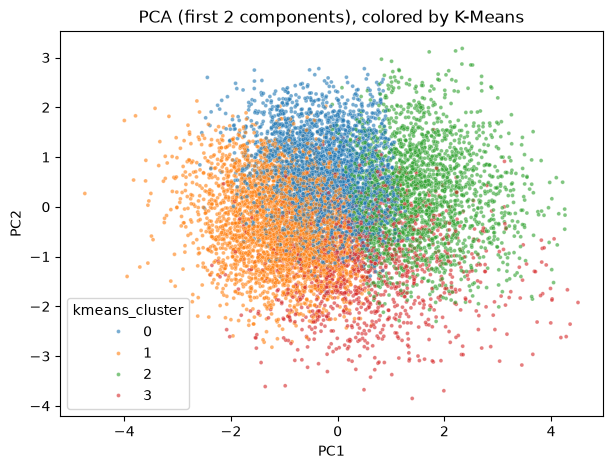

In [2]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x=Xs[:, 0], y=Xs[:, 1], hue=sample["kmeans_cluster"],
                palette="tab10", s=8, alpha=0.6)
plt.title("PCA (first 2 components), colored by K-Means")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.savefig(config.FIGURES_DIR / "pca_2d.png", dpi=150)
plt.show()

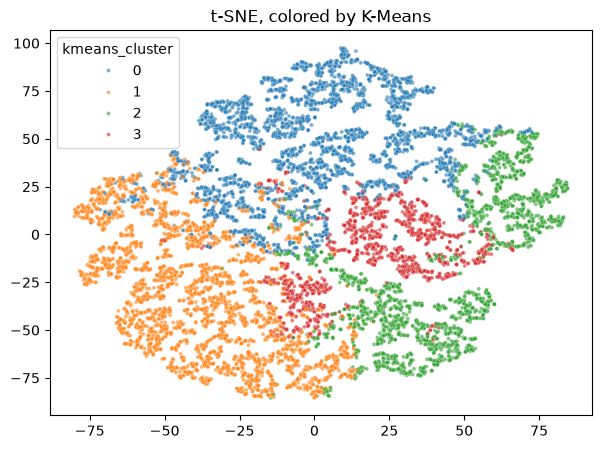

In [3]:
tsne = TSNE(n_components=2, perplexity=30, init="pca",
            random_state=config.RANDOM_STATE)
emb_tsne = tsne.fit_transform(Xs)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=emb_tsne[:, 0], y=emb_tsne[:, 1],
                hue=sample["kmeans_cluster"], palette="tab10", s=8, alpha=0.6)
plt.title("t-SNE, colored by K-Means")
plt.savefig(config.FIGURES_DIR / "tsne.png", dpi=150)
plt.show()

D:\GUVI\Project_3\credit-portfolio-segmentation\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


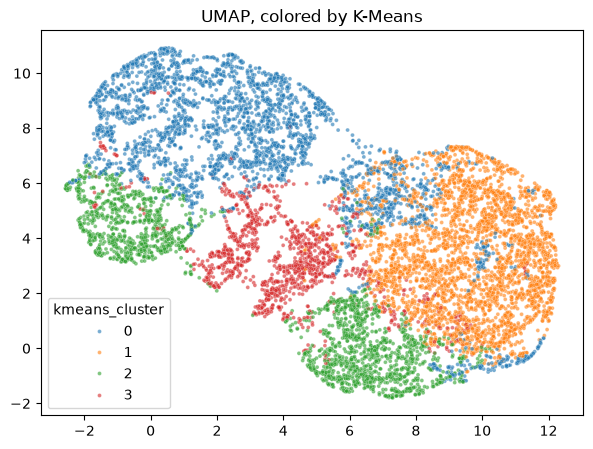

In [4]:
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                    random_state=config.RANDOM_STATE)
emb_umap = reducer.fit_transform(Xs)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=emb_umap[:, 0], y=emb_umap[:, 1],
                hue=sample["kmeans_cluster"], palette="tab10", s=8, alpha=0.6)
plt.title("UMAP, colored by K-Means")
plt.savefig(config.FIGURES_DIR / "umap.png", dpi=150)
plt.show()

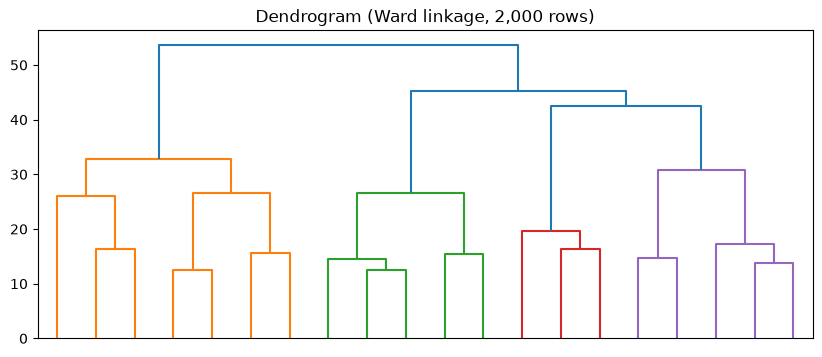

hier_cluster
0    3227
1    2452
2    3442
3     879
Name: count, dtype: int64


In [5]:
# Dendrogram on a smaller subset (2,000 rows) so it stays readable
Z = linkage(Xs[:2000], method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=20, no_labels=True)
plt.title("Dendrogram (Ward linkage, 2,000 rows)")
plt.savefig(config.FIGURES_DIR / "dendrogram.png", dpi=150)
plt.show()

hier = AgglomerativeClustering(n_clusters=4, linkage="ward")
sample["hier_cluster"] = hier.fit_predict(Xs)
print(sample["hier_cluster"].value_counts().sort_index())

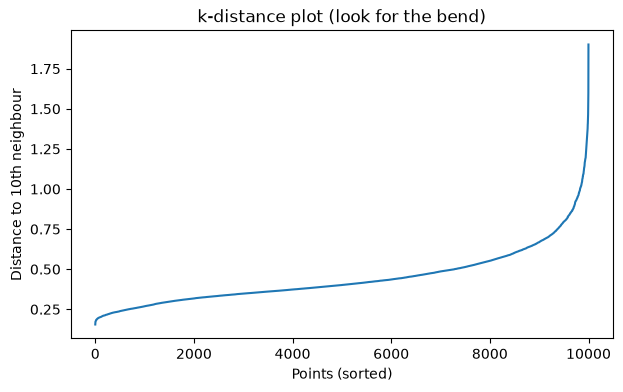

eps=0.3: clusters=32, noise=73.1%
eps=0.4: clusters=14, noise=33.5%
eps=0.5: clusters=5, noise=15.1%
eps=0.6: clusters=3, noise=7.3%
eps=0.8: clusters=1, noise=1.7%
eps=1.0: clusters=1, noise=0.4%


In [6]:
MIN_SAMPLES = 10
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xs)
dist, _ = nn.kneighbors(Xs)
k_dist = np.sort(dist[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(k_dist)
plt.ylabel(f"Distance to {MIN_SAMPLES}th neighbour")
plt.xlabel("Points (sorted)")
plt.title("k-distance plot (look for the bend)")
plt.savefig(config.FIGURES_DIR / "dbscan_kdistance.png", dpi=150)
plt.show()

for eps in [0.3, 0.4, 0.5, 0.6, 0.8, 1.0]:
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Xs)
    print(f"eps={eps}: clusters={len(set(lab) - {-1})}, noise={round((lab == -1).mean() * 100, 1)}%")

In [10]:
EPS = 0.8   # change after looking at Cell 6

sample["dbscan_cluster"] = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Xs)
print(sample["dbscan_cluster"].value_counts().sort_index())

dbscan_cluster
-1     173
 0    9827
Name: count, dtype: int64


In [11]:
def summarize(labels, name):
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    sil = silhouette_score(Xs[mask], labels[mask]) if n_clusters > 1 else np.nan
    return {"algorithm": name, "clusters": n_clusters,
            "noise_%": round((~mask).mean() * 100, 1),
            "silhouette": round(sil, 4)}

comparison = pd.DataFrame([
    summarize(sample["kmeans_cluster"].to_numpy(), "K-Means"),
    summarize(sample["hier_cluster"].to_numpy(), "Hierarchical (Ward)"),
    summarize(sample["dbscan_cluster"].to_numpy(), "DBSCAN"),
])
print(comparison)

for col in ["kmeans_cluster", "hier_cluster", "dbscan_cluster"]:
    print(col)
    print(sample.groupby(col)["Default"].agg(["mean", "size"]).round(3))

             algorithm  clusters  noise_%  silhouette
0              K-Means         4      0.0      0.2182
1  Hierarchical (Ward)         4      0.0      0.1755
2               DBSCAN         1      1.7         NaN
kmeans_cluster
                 mean  size
kmeans_cluster             
0               0.209  3212
1               0.221  3298
2               0.226  2168
3               0.081  1322
hier_cluster
               mean  size
hier_cluster             
0             0.206  3227
1             0.235  2452
2             0.201  3442
3             0.074   879
dbscan_cluster
                 mean  size
dbscan_cluster             
-1              0.145   173
 0              0.201  9827


In [12]:
noise = sample[sample["dbscan_cluster"] == -1]
normal = sample[sample["dbscan_cluster"] != -1]

anom = pd.DataFrame({
    "anomalies": noise[NUM_FEATURES + ["revenue", "Default"]].mean(),
    "normal": normal[NUM_FEATURES + ["revenue", "Default"]].mean(),
}).round(2)
print(len(noise), "anomalies")
print(anom)

173 anomalies
                  anomalies    normal
revenue_log           11.17     11.09
dti_n                 16.29     18.07
loan_amnt          19859.10  14144.95
fico_n               778.71    697.50
emp_length_years       4.79      5.99
revenue           108573.66  74505.76
Default                0.14      0.20
